# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [4]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.12.1


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [5]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Writing Hello.java


In [6]:
!java Hello.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.12.1


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [7]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Writing TariffBefore.java


In [8]:
!java TariffBefore.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [9]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Writing TariffAfter.java


In [10]:
!java TariffAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [16]:
!rm -rf /var/lib/apt/lists/* && apt-get update -qq && apt-get install -y plantuml > /dev/null && echo "PlantUML установлен"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
PlantUML установлен


In [17]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


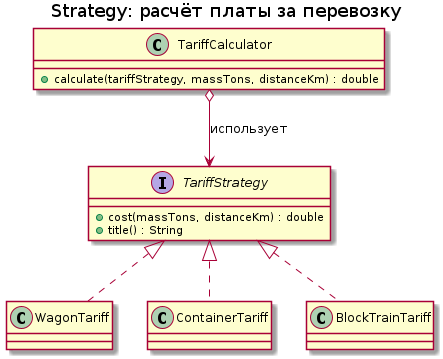

In [18]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?

Ответ:В коде «до» – единственный метод cost() в классе TariffBefore: пришлось бы добавить ещё одну ветку else if (shipmentType.equals("REFRIGERATED")). То есть правится уже работающий метод, который отвечает сразу и за выбор варианта, и за расчёт – нарушение OCP и SRP.
В коде «после» – ни один существующий класс менять не надо. Создаётся новый класс RefrigeratedTariff implements TariffStrategy с формулой и title(), и он регистрируется в каталоге в main (или добавляется в список стратегий). TariffCalculator, WagonTariff, ContainerTariff, BlockTrainTariff остаются нетронутыми – это и есть соблюдение принципа открытости/закрытости.

2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?

Ответ:Это эталон поведения для характеризующих тестов. Тесты сравнивают tariffCalculator.calculate(...) с legacyCost(...) и доказывают, что после рефакторинга числа не изменились – то есть рефакторинг «поведение сохраняет». После того как характеризующие тесты написаны и прошли, legacyCost можно удалить (или вынести в отдельный тестовый класс). Пока идёт учебная проверка – его держат в файле, чтобы было с чем сравнивать.

3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?

Ответ*tariffCatalog.get("НЕИЗВЕСТНЫЙ") вернёт null. Тогда tariffCalculator.calculate(null, ...) бросит NullPointerException при вызове tariffStrategy.cost(...) – это неинформативная ошибка, «падает непонятно где».
Обрабатывать надо явно, одним из способов:
проверка на null с осмысленным сообщением:
TariffStrategy strategy = tariffCatalog.get(type);
if (strategy == null) {
    throw new IllegalArgumentException("Неизвестный вид отправки: " + type);
}
getOrDefault со стратегией-заглушкой (например, UnknownTariff, возвращающей 0 или бросающей исключение);
Optional<TariffStrategy> в каталоге – тогда отсутствие варианта видно по типу и обязательно к обработке;
enum-ключ вместо строки – тогда неизвестного вида отправки в принципе не бывает (компилятор не даст).


---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [19]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Writing FactoryBefore.java


In [20]:
!java FactoryBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы
Неизвестный тип вагона: HOPPER


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [41]:
%%writefile FactoryAfter.java
// Код «после»: создание груза вынесено в фабричный метод.
// Клиент (main) не знает конкретных классов и не содержит ветвления по типу.
import java.util.LinkedHashMap;
import java.util.Map;

public class FactoryAfter {

    private static int failedChecks = 0;

    static final String KEY_BOX       = "BOX";
    static final String KEY_PALLET    = "PALLET";
    static final String KEY_CONTAINER = "CONTAINER";
    static final String KEY_BARREL    = "BARREL";

    public static void main(String[] args) {

        Map<String, CargoFactory> factoryCatalog = buildCatalog();
        Map<String, Double> capacities = buildCapacities();

        System.out.println("--- Тара через фабричный метод ---");
        for (Map.Entry<String, CargoFactory> entry : factoryCatalog.entrySet()) {
            Cargo cargo = entry.getValue().create(capacities.get(entry.getKey()));
            System.out.println(entry.getKey() + ": " + cargo.describe());
        }

        System.out.println();
        System.out.println("--- Проверки ---");

        runChecks(factoryCatalog);
        finish();
    }

    // Финальная проверка вынесена из main, чтобы в main не было "if"/"switch"
    static void finish() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- инициализация каталога и данных вынесена из main ---

    static Map<String, CargoFactory> buildCatalog() {
        Map<String, CargoFactory> catalog = new LinkedHashMap<>();
        catalog.put(KEY_BOX,       new BoxFactory());
        catalog.put(KEY_PALLET,    new PalletFactory());
        catalog.put(KEY_CONTAINER, new ContainerFactory());
        catalog.put(KEY_BARREL,    new BarrelFactory());
        return catalog;
    }

    static Map<String, Double> buildCapacities() {
        Map<String, Double> capacities = new LinkedHashMap<>();
        capacities.put(KEY_BOX,       25.0);
        capacities.put(KEY_PALLET,    800.0);
        capacities.put(KEY_CONTAINER, 20000.0);
        capacities.put(KEY_BARREL,    200.0);
        return capacities;
    }

    // --- проверки вынесены из main ---

    static void runChecks(Map<String, CargoFactory> factoryCatalog) {
        Cargo box       = factoryCatalog.get(KEY_BOX).create(25.0);
        Cargo pallet    = factoryCatalog.get(KEY_PALLET).create(800.0);
        Cargo container = factoryCatalog.get(KEY_CONTAINER).create(20000.0);
        Cargo barrel    = factoryCatalog.get(KEY_BARREL).create(200.0);

        check("коробка: описание не пустое",
                box.describe() != null && !box.describe().isEmpty());
        check("коробка: описание содержит вместимость 25",
                box.describe().contains("25"));
        check("паллета: описание содержит вместимость 800",
                pallet.describe().contains("800"));
        check("контейнер: описание содержит вместимость 20000",
                container.describe().contains("20000"));

        check("коробка: объект — Box",            isType(box,       "Box"));
        check("паллета: объект — Pallet",         isType(pallet,    "Pallet"));
        check("контейнер: объект — Container",    isType(container, "Container"));
        check("бочка (4-й тип): объект — Barrel", isType(barrel,    "Barrel"));
        check("бочка: описание содержит вместимость 200",
                barrel.describe().contains("200"));
    }

    static boolean isType(Object obj, String simpleName) {
        return obj.getClass().getSimpleName().equals(simpleName);
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }
}

// --- участники паттерна Factory Method ---

interface Cargo {
    String describe();
}

interface CargoFactory {
    Cargo create(double capacityKg);
}

class Box implements Cargo {
    private final double capacityKg;
    Box(double capacityKg) { this.capacityKg = capacityKg; }
    public String describe() {
        return "вместимость " + capacityKg + " кг, мелкоштучный груз";
    }
}

class Pallet implements Cargo {
    private final double capacityKg;
    Pallet(double capacityKg) { this.capacityKg = capacityKg; }
    public String describe() {
        return "вместимость " + capacityKg + " кг, пакетированный груз";
    }
}

class Container implements Cargo {
    private final double capacityKg;
    Container(double capacityKg) { this.capacityKg = capacityKg; }
    public String describe() {
        return "вместимость " + capacityKg + " кг, крупнотоннажный груз";
    }
}

class Barrel implements Cargo {
    private final double capacityKg;
    Barrel(double capacityKg) { this.capacityKg = capacityKg; }
    public String describe() {
        return "вместимость " + capacityKg + " кг, наливной/сыпучий груз";
    }
}

class BoxFactory implements CargoFactory {
    public Cargo create(double capacityKg) { return new Box(capacityKg); }
}

class PalletFactory implements CargoFactory {
    public Cargo create(double capacityKg) { return new Pallet(capacityKg); }
}

class ContainerFactory implements CargoFactory {
    public Cargo create(double capacityKg) { return new Container(capacityKg); }
}

class BarrelFactory implements CargoFactory {
    public Cargo create(double capacityKg) { return new Barrel(capacityKg); }
}

Overwriting FactoryAfter.java


In [42]:
!java FactoryAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Тара через фабричный метод ---
BOX: вместимость 25.0 кг, мелкоштучный груз
PALLET: вместимость 800.0 кг, пакетированный груз
CONTAINER: вместимость 20000.0 кг, крупнотоннажный груз
BARREL: вместимость 200.0 кг, наливной/сыпучий груз

--- Проверки ---
[OK]   коробка: описание не пустое
[OK]   коробка: описание содержит вместимость 25
[OK]   паллета: описание содержит вместимость 800
[OK]   контейнер: описание содержит вместимость 20000
[OK]   коробка: объект — Box
[OK]   паллета: объект — Pallet
[OK]   контейнер: объект — Container
[OK]   бочка (4-й тип): объект — Barrel
[OK]   бочка: описание содержит вместимость 200

Все проверки пройдены.


In [43]:
%%writefile factory.puml
@startuml
title Factory Method: создание тары (склад, вариант 6)

interface Packaging {
  +description() : String
  +capacityKg() : double
}

interface PackagingCreator {
  +createPackaging(capacityKg) : Packaging
}

class Box
class Pallet
class Container
class Barrel

class BoxCreator
class PalletCreator
class ContainerCreator
class BarrelCreator

Packaging <|.. Box
Packaging <|.. Pallet
Packaging <|.. Container
Packaging <|.. Barrel

PackagingCreator <|.. BoxCreator
PackagingCreator <|.. PalletCreator
PackagingCreator <|.. ContainerCreator
PackagingCreator <|.. BarrelCreator

BoxCreator ..> Box : создаёт
PalletCreator ..> Pallet : создаёт
ContainerCreator ..> Container : создаёт
BarrelCreator ..> Barrel : создаёт
@enduml

Overwriting factory.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


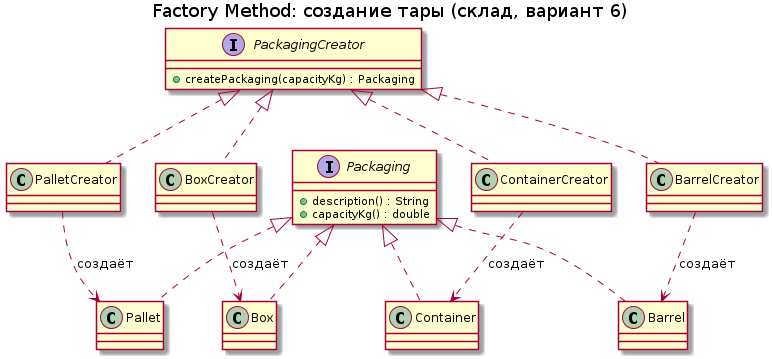

In [39]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня): При new CoveredWagon(...) вызывающий код жёстко зависит от конкретного класса: чтобы добавить HopperWagon, надо править именно этот код (та же болезнь, что if/else по типу – нарушение OCP). Фабричный метод прячет конкретный класс за абстракцией WagonCreator.createWagon(...): main работает с интерфейсами WagonCreator и Wagon, а выбор класса – забота конкретного создателя. Новый тип (HopperWagon) добавляется новым классом-продуктом и новым создателем, существующий код не правится. Это также упрощает тестирование: создателя можно подменить заглушкой.
Когда фабрика излишня. Когда тип объекта один и он не меняется; когда объект создаётся в единственном месте и без полиморфизма; когда нет требования «добавлять без правки старого». В таких случаях new короче и понятнее, а фабрика – «преждевременное усложнение»: лишний интерфейс и N классов-создателей ради одного new.


---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [24]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Writing ObserverBefore.java


In [25]:
!java ObserverBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[табло]  Поезд 6701 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 6701


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [26]:
%%writefile ObserverAfter.java
// Вариант 6 (Склад): событие — «запас ниже нормы».
// Структура паттерна Observer та же, что в образце раздела 4:
// вместо прибытия поезда — падение запаса, вместо Station — Warehouse.
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {
        Warehouse warehouse = new Warehouse("Склад №1");

        StockBoard   board   = new StockBoard();
        StockJournal journal = new StockJournal();
        StockMailing mailing = new StockMailing();

        warehouse.addListener(board);
        warehouse.addListener(journal);
        warehouse.addListener(mailing);

        System.out.println("--- Остаток упал ниже нормы ---");
        warehouse.consume("Гвозди 100 мм", 30.0, 75.0);      // 30 < 75 → событие
        check("после одного события журнал получил ровно одну запись", journal.size() == 1);

        System.out.println();
        System.out.println("--- Остаток выше нормы, события нет ---");
        warehouse.consume("Шурупы 4x40", 10.0, 5.0);         // 10 > 5 → тишина
        check("при остатке выше нормы журнал не вырос", journal.size() == 1);

        warehouse.removeListener(board);
        System.out.println();
        System.out.println("--- Табло отписано, событие №2 ---");
        int boardBefore = board.lines();
        warehouse.consume("Болты М8", 40.0, 80.0);           // 40 < 80 → событие
        check("после отписки табло не получало событий", board.lines() == boardBefore);
        check("журнал получил вторую запись", journal.size() == 2);

        check("все подписчики получили один и тот же товар",
                journal.last().contains("Болты М8") && mailing.last().contains("Болты М8"));

        AsuListener asu = new AsuListener();
        warehouse.addListener(asu);
        System.out.println();
        System.out.println("--- Добавлен четвёртый наблюдатель (АСУ) ---");
        warehouse.consume("Гайки М8", 90.0, 60.0);           // 90 > 60 → тишина
        check("АСУ не получила событие, когда запас в норме", asu.count() == 0);
        warehouse.consume("Гайки М8", 10.0, 60.0);           // 10 < 60 → событие
        check("АСУ получила событие без изменения класса Warehouse", asu.count() == 1);

        System.out.println();
        System.out.println("Порядок получения события: табло -> журнал -> рассылка (порядок подписки).");

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println("Все проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) failedChecks++;
    }
}

// --- Наблюдатель ---
interface StockListener {
    void onStockBelowNorm(String warehouseName, String itemName, double remainingKg, double normKg);
}

// --- Субъект: не знает, кто именно его слушает ---
class Warehouse {
    private final String warehouseName;
    private final List<StockListener> listeners = new ArrayList<>();

    Warehouse(String warehouseName) { this.warehouseName = warehouseName; }

    void addListener(StockListener listener)    { listeners.add(listener); }
    void removeListener(StockListener listener) { listeners.remove(listener); }

    void consume(String itemName, double remainingKg, double normKg) {
        System.out.println("Списано: " + itemName + ", остаток " + remainingKg + " кг, норма " + normKg + " кг");
        if (remainingKg < normKg) {
            for (StockListener listener : listeners) {
                listener.onStockBelowNorm(warehouseName, itemName, remainingKg, normKg);
            }
        }
    }
}

// --- Наблюдатели ---
class StockBoard implements StockListener {
    private int lines = 0;
    public void onStockBelowNorm(String warehouseName, String itemName, double remainingKg, double normKg) {
        lines++;
        System.out.println("[табло]  " + warehouseName + ": " + itemName
                + " — остаток " + remainingKg + " кг < нормы " + normKg + " кг");
    }
    int lines() { return lines; }
}

class StockJournal implements StockListener {
    private final List<String> entries = new ArrayList<>();
    public void onStockBelowNorm(String warehouseName, String itemName, double remainingKg, double normKg) {
        entries.add(warehouseName + ": " + itemName + " ниже нормы (" + remainingKg + " < " + normKg + ")");
        System.out.println("[журнал] " + entries.get(entries.size() - 1));
    }
    int size() { return entries.size(); }
    String last() { return entries.get(entries.size() - 1); }
}

class StockMailing implements StockListener {
    private final List<String> sent = new ArrayList<>();
    public void onStockBelowNorm(String warehouseName, String itemName, double remainingKg, double normKg) {
        sent.add("рассылка: " + itemName + " на " + warehouseName + " ниже нормы");
        System.out.println("[рассылка] " + sent.get(sent.size() - 1));
    }
    String last() { return sent.get(sent.size() - 1); }
}

// Четвёртый наблюдатель — добавлен новым классом, Warehouse не изменён
class AsuListener implements StockListener {
    private int count = 0;
    public void onStockBelowNorm(String warehouseName, String itemName, double remainingKg, double normKg) {
        count++;
        System.out.println("[АСУ] передано в учётную систему: " + itemName + " @ " + warehouseName);
    }
    int count() { return count; }
}

Writing ObserverAfter.java


In [27]:
!java ObserverAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Остаток упал ниже нормы ---
Списано: Гвозди 100 мм, остаток 30.0 кг, норма 75.0 кг
[табло]  Склад №1: Гвозди 100 мм — остаток 30.0 кг < нормы 75.0 кг
[журнал] Склад №1: Гвозди 100 мм ниже нормы (30.0 < 75.0)
[рассылка] рассылка: Гвозди 100 мм на Склад №1 ниже нормы
[OK]   после одного события журнал получил ровно одну запись

--- Остаток выше нормы, события нет ---
Списано: Шурупы 4x40, остаток 10.0 кг, норма 5.0 кг
[OK]   при остатке выше нормы журнал не вырос

--- Табло отписано, событие №2 ---
Списано: Болты М8, остаток 40.0 кг, норма 80.0 кг
[журнал] Склад №1: Болты М8 ниже нормы (40.0 < 80.0)
[рассылка] рассылка: Болты М8 на Склад №1 ниже нормы
[OK]   по

In [28]:
%%writefile observer.puml
@startuml
title Observer: запас ниже нормы (склад, вариант 6)

interface StockListener {
  +onStockBelowNorm(warehouseName, itemName, remainingKg, normKg) : void
}

class Warehouse {
  -listeners : List<StockListener>
  +addListener(listener) : void
  +removeListener(listener) : void
  +consume(itemName, remainingKg, normKg) : void
}

class StockBoard
class StockJournal
class StockMailing
class AsuListener

Warehouse o--> StockListener : оповещает
StockListener <|.. StockBoard
StockListener <|.. StockJournal
StockListener <|.. StockMailing
StockListener <|.. AsuListener
@enduml

Writing observer.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


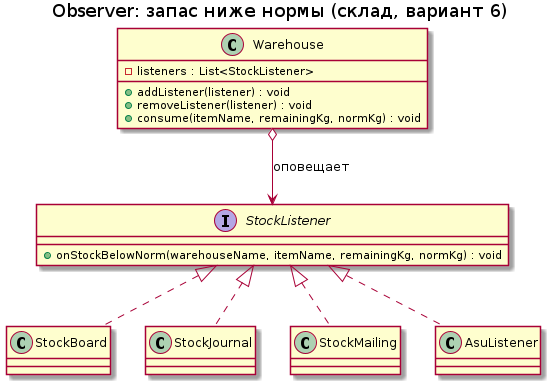

In [29]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка):В коде «до» класс Station сам перечислял всех получателей (System.out.println для табло и журнала). Любой новый получатель требовал правки метода trainArrived – жёсткая связь субъекта с конкретными получателями, нарушение OCP и SRP. После рефакторинга Station зависит только от абстракции ArrivalListener, а не от конкретных классов. Новый наблюдатель (AsuListener) добавляется новым классом, класс Station не меняется; подписка/отписка (addListener/removeListener) – гибкий механизм.
Какие новые проблемы создал Observer:

1.	Порядок уведомлений. Он равен порядку подписки и по смыслу не гарантирован. Если логика зависит от того, кто первым узнал о событии (например, АСУ должна раньше табло), это надо документировать или сортировать подписчиков по приоритету.
2.	Ошибка в одном подписчике. Если onTrainArrived бросит исключение, цикл for прервётся, и остальные подписчики событие не получат. Нужно оборачивать каждый вызов в try/catch, чтобы сбой одного получателя не ломал остальных.
3.	Забытая отписка. Station держит сильные ссылки на наблюдателей в ArrayList. Если подписчик больше не нужен, но removeListener не вызван, объект не соберётся сборщиком мусора – утечка памяти. Решения: WeakReference, явная отписка (close()/try-with-resources), либо платформенные event-механизмы.
4.	Порядок и дубликаты. ArrayList позволяет подписаться дважды – событие придёт дважды. Если это не нужно, хранить наблюдателей в Set или проверять наличие перед добавлением.


---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица


| Паттерн | Проблема кода «до» | Что добавляется без правки старого | Чем платим | Где применим |
|---|---|---|---|---|
| **Strategy** | `if/else` в `cost()`:<br>• выбор + расчёт в одном методе<br>• нарушение OCP/SRP<br>• новый вид → `0.0` | • новый класс `implements TariffStrategy`<br>• `TariffCalculator` и старые стратегии не меняются | • +1 интерфейс<br>• +N классов<br>• выбор в `main` | • правило размещения на складе (FIFO, ABC)<br>• вариант 6 |
| **Factory Method** | `switch`/`if` по типу:<br>• «неизвестный тип» для нового<br>• нарушение OCP | • новый продукт + создатель<br>• старые `Packaging`/`PackagingCreator` не меняются<br>• `Barrel`/`BarrelCreator` — отдельно | • +2 класса на каждый тип<br>• косвенный вызов | • создание тары: `Box`, `Pallet`, `Container`, `Barrel` |
| **Observer** | субъект сам перечисляет получателей:<br>• жёсткая связь `Warehouse` с табло/журналом/рассылкой<br>• нарушение OCP/DIP | • новый класс `implements StockListener`<br>• `Warehouse` не меняется | • порядок = порядок подписки<br>• ошибка в одном рвёт цикл<br>• забытая отписка → утечка | • оповещение «запас ниже нормы»: табло, журнал, рассылка, АСУ |




### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?

   **Ответ:** Разбор типа if/else (или switch) нарушает Open/Closed Principle (OCP) – класс открыт для изменения: каждый новый вариант заставляет править уже работающий метод. Одновременно страдает Single Responsibility Principle (SRP) – метод и выбирает вариант, и выполняет работу (у Strategy), и создаёт объект (у Factory).
Strategy восстанавливает OCP: каждый вариант расчёта – отдельный класс за интерфейсом; новый вариант = новый класс, контекст (TariffCalculator) не меняется. SRP тоже восстанавливается: выбор – в вызывающем коде, расчёт – в стратегии.
Factory Method восстанавливает OCP на этапе создания: новый тип = новый продукт + новый создатель; вызывающий код (main) зависит от абстракций WagonCreator/Wagon.
Observer восстанавливает OCP и DIP (Dependency Inversion): субъект зависит от абстракции ArrivalListener, а не от конкретных получателей; новый получатель = новый класс, субъект не меняется.

2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?

   **Ответ:** Static factory method – это просто static-метод, возвращающий объект (например, List.of(...), Integer.valueOf(...)). Он не полиморфен: нельзя переопределить создание в подклассе, нельзя подменить создателя заглушкой в тестах. Удобен, когда тип один и логика создания простая.
Factory Method – полиморфный создатель: интерфейс/абстрактный класс WagonCreator с методом createWagon(...), конкретные подклассы решают, что именно создать. Даёт расширяемость (новый тип – новый создатель) и тестируемость (создателя можно подменить).
Abstract Factory – «фабрика фабрик»: интерфейс, создающий семейство взаимосвязанных продуктов (createWagon(), createLocomotive(), createTrack()). Применяется, когда продукты должны быть согласованы между собой (один стиль/поколение). Factory Method создаёт один продукт.

3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?

   **Ответ:** Strategy – взаимозаменяемые алгоритмы. Выбор делает клиент (внешний код), и выбранная стратегия обычно не меняется сама. Цель – убрать if/else по варианту расчёта, дать альтернативные алгоритмы.
State – состояния объекта, и переходы между ними происходят внутри (объект сам переключает состояние по событиям). Поведение определяется текущим состоянием; клиент обычно не знает, в каком состоянии объект. Цель – моделировать конечный автомат.

4. Почему Observer может привести к утечке памяти и как этого избежать?

   **Ответ:** Субъект хранит сильные ссылки на наблюдателей (обычно в ArrayList). Если наблюдатель больше не нужен, но removeListener не вызван, объект не будет собран GC – утечка памяти (особенно опасно для долгоживущих субъектов и короткоживущих подписчиков). Способы избежать:
WeakReference в списке подписчиков (WeakHashMap или List<WeakReference<Listener>> с очисткой) – GC соберёт наблюдателя, когда на него не останется сильных ссылок;

явная отписка – removeListener в finally/close()/try-with-resources, либо автоотписка при уничтожении наблюдателя;

платформенные механизмы – EventListener в Java (слабая ссылка), addEventListener/removeEventListener в браузере и т. п.;

не забывать про дубликаты: хранить подписчиков в Set, а не List, если повторная подписка не нужна.

5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?

   **Ответ:** Пример: в коде «до» у нас один тип вагона и один вид расчёта, и по требованиям он никогда не изменится. Вводить Factory Method (интерфейс Wagon + WagonCreator + 2 класса вместо одного new CoveredWagon(...)) или Strategy (интерфейс + класс вместо одной формулы) – это лишние сущности, косвенность и файлы без пользы. Аналогично: Observer там, где событие одно и получатель один – проще прямой вызов.

Преждевременное усложнение (over-engineering) – введение абстракций и паттернов «на будущее», когда реальной точки расширения ещё нет. Признаки: интерфейс с одной реализацией, фабрика, создающая один тип, «на всякий случай» добавленные слои. Паттерн оправдан, когда есть реальная боль: 3+ варианта, требование «добавлять без правки старого», несколько получателей события. Пока боли нет – if/new/прямой вызов короче, понятнее и дешевле в поддержке.


### 5.3 Три вывода по работе в целом
1. Паттерн – это ответ на конкретную боль, а не «красивый код». Разбор типа, жёсткая связь, дублирование выбора – вот что лечат Strategy, Factory Method и Observer. Пока боли нет, паттерн добавляет классов и косвенности, а пользы не приносит.
2. Главный признак успешного применения – новое требование добавляется новым классом, а не правкой старого. Рефрижератор (Strategy), зерновоз HopperWagon (Factory Method), АСУ-наблюдатель (Observer) – все добавлены без изменения существующих классов. Именно это доказывают характеризующие тесты и тест открытости/закрытости.
3. У каждого паттерна есть цена, и её надо называть явно. Strategy – выбор варианта уезжает в вызывающий код; Factory Method – +2 класса на тип; Observer – порядок уведомлений, ошибки в подписчиках, утечки при забытой отписке. Умение видеть цену и есть разница между «применил паттерн» и «применил паттерн к месту».


---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [44]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = "Шуст Полина Александровна"  #@param {type:"string"}
Группа_исполнителя = "СИ-41"  #@param {type:"string"}
Номер_варианта = 6  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Шуст Полина Александровна, группа СИ-41, вариант 6 |
| Дата и время отчёта (UTC) | 2026-11-17 07:47 |
| Версия Java | openjdk version "21.0.13.0.3" 2026-10-24 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 9 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 7 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |